In [142]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Loading Data

In [153]:
base_path = r"D:\WKESKIN\CENTENNIAL\2025FALL\COMP258-NeuralNetwork\ASSIGNMENTS\Assignment03"
data_path = os.path.join(base_path, "Dataset")

print("Data path:", data_path)
print("Exists?", os.path.isdir(data_path))

categories = os.listdir(data_path)
categories = [c for c in categories if os.path.isdir(os.path.join(data_path, c))]
print("Categories found:", categories)

labels = [i for i in range(len(categories))]
label_dict = dict(zip(categories, labels))
print("Label mapping:", label_dict)

Data path: D:\WKESKIN\CENTENNIAL\2025FALL\COMP258-NeuralNetwork\ASSIGNMENTS\Assignment03\Dataset
Exists? True
Categories found: ['without_mask', 'with_mask']
Label mapping: {'without_mask': 0, 'with_mask': 1}


Image counts per category: {'without_mask': 5521, 'with_mask': 5521}


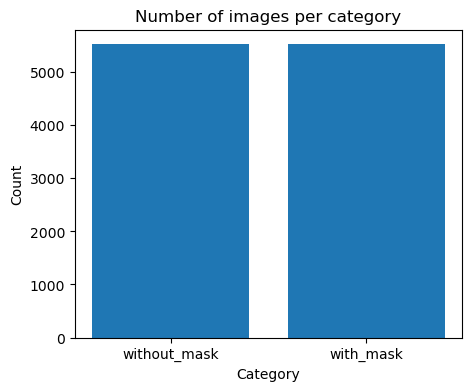

In [154]:
valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')

counts = {}
for cat in categories:
    folder = os.path.join(data_path, cat)
    n_files = sum(
        1 for f in os.listdir(folder)
        if f.lower().endswith(valid_exts)
    )
    counts[cat] = n_files

print("Image counts per category:", counts)

plt.figure(figsize=(5, 4))
plt.bar(counts.keys(), counts.values())
plt.title("Number of images per category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

# Preprocessing

In [155]:
IMG_SIZE = 100
RANDOM_SEED = 96

all_images = []
all_labels = []

for cat in categories:
    folder = os.path.join(data_path, cat)
    label = label_dict[cat]
    
    for fname in os.listdir(folder):
        if not fname.lower().endswith(valid_exts):
            continue
        
        fpath = os.path.join(folder, fname)
        
        # Read image with OpenCV
        img = cv2.imread(fpath)
        if img is None:
            print("Skipping unreadable image:", fpath)
            continue
        
        # Conversion of RGB image to Gray image
        # OpenCV loads as BGR, so BGR -> GRAY
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        
        # Resize to 100x100 (as in the article)
        gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
        
        # Normalize pixel values to [0, 1]
        gray = gray.astype("float32") / 255.0
        
        # Append
        all_images.append(gray)
        all_labels.append(label)

all_images = np.array(all_images)   # shape: (N, 100, 100)
all_labels = np.array(all_labels)   # shape: (N,)

print("Raw image array shape:", all_images.shape)
print("Labels shape:", all_labels.shape)

Raw image array shape: (11042, 100, 100)
Labels shape: (11042,)


In [156]:
# Image reshaping
# Add channel dimension: (N, 100, 100, 1)
data = np.reshape(all_images, (all_images.shape[0], IMG_SIZE, IMG_SIZE, 1))
print("Reshaped data:", data.shape)

# Convert labels to categorical (one-hot) for 2 classes
num_classes = len(categories)
labels_cat = to_categorical(all_labels, num_classes=num_classes)
print("Categorical labels shape:", labels_cat.shape)

Reshaped data: (11042, 100, 100, 1)
Categorical labels shape: (11042, 2)


In [157]:
# First split: 10% test
X_trainval, X_test, y_trainval, y_test = train_test_split(
    data,
    labels_cat,
    test_size=0.10,
    random_state=RANDOM_SEED,
    stratify=all_labels
)

# Second split: 20% of trainval as validation (so 72/18/10 overall)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.20,            # 20% of 90% = 18% of total
    random_state=RANDOM_SEED,
    stratify=np.argmax(y_trainval, axis=1)
)

print("Final shapes:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "y_val:",   y_val.shape)
print("X_test: ", X_test.shape,  "y_test:",  y_test.shape)
print("Train %:", X_train.shape[0] / data.shape[0])
print("Val %:  ", X_val.shape[0]   / data.shape[0])
print("Test %: ", X_test.shape[0]  / data.shape[0])


Final shapes:
X_train: (7949, 100, 100, 1) y_train: (7949, 2)
X_val:   (1988, 100, 100, 1) y_val: (1988, 2)
X_test:  (1105, 100, 100, 1) y_test: (1105, 2)
Train %: 0.7198877015033508
Val %:   0.1800398478536497
Test %:  0.10007245064299945


# Sample images preview

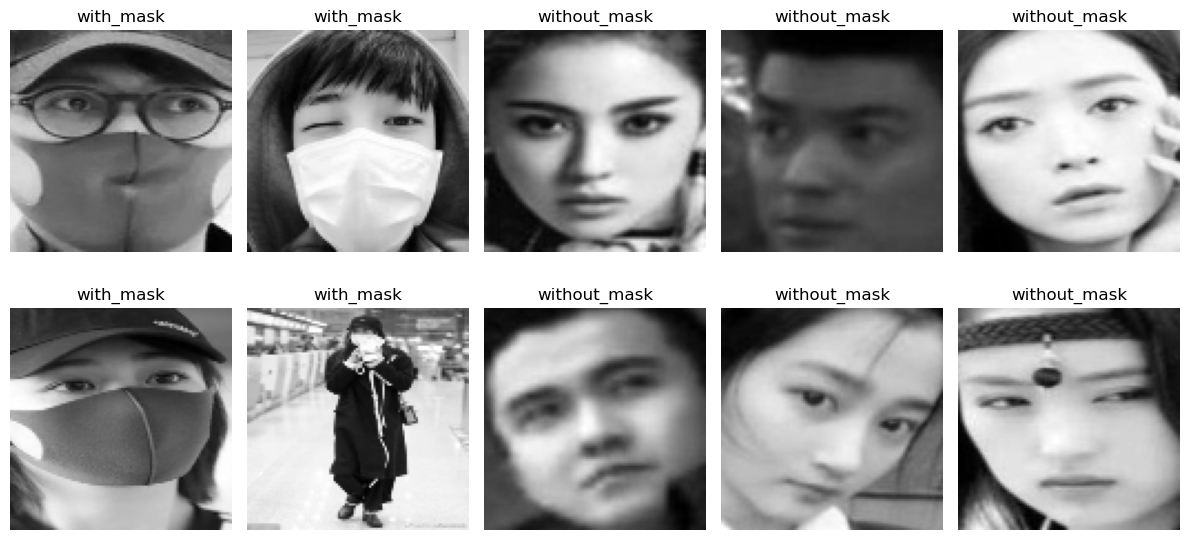

In [182]:
def show_processed_samples(images, labels, class_names, n=10):
    # Create shuffled indices
    idx = np.random.permutation(len(images))[:n]
    
    plt.figure(figsize=(12, 6))
    
    for i, index in enumerate(idx):
        img = images[index]
        label = labels[index]

        plt.subplot(2, 5, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(class_names[label])
        plt.axis("off")

    plt.tight_layout()
    plt.show()
show_processed_samples(all_images, all_labels, categories, n=10)

# Build Model

In [159]:
num_classes = y_train.shape[1]
model = models.Sequential([
    # 1st conv layer – 200 filters
    layers.Conv2D(200, (3, 3), activation='relu', input_shape=(100, 100, 1)),
    layers.MaxPooling2D((2, 2)),
    
    # 2nd conv layer – 100 filters
    layers.Conv2D(100, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten + classifier
    layers.Flatten(),
    layers.Dense(64, activation='relu'),     # 64 neurons as in the algorithm
    layers.Dropout(0.5),

    # Final layer: 2 outputs for 2 categories (with_mask, without_mask)
    layers.Dense(num_classes, activation='softmax')      
])

model.summary()

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_14 (Conv2D)          (None, 98, 98, 200)       2000      
                                                                 
 max_pooling2d_14 (MaxPooli  (None, 49, 49, 200)       0         
 ng2D)                                                           
                                                                 
 conv2d_15 (Conv2D)          (None, 47, 47, 100)       180100    
                                                                 
 max_pooling2d_15 (MaxPooli  (None, 23, 23, 100)       0         
 ng2D)                                                           
                                                                 
 flatten_7 (Flatten)         (None, 52900)             0         
                                                                 
 dense_14 (Dense)            (None, 64)               

In [164]:
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [165]:
# Train Model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
249/249 [==============================] - 248s 990ms/step - loss: 0.4700 - accuracy: 0.7990 - val_loss: 0.3849 - val_accuracy: 0.8124
Epoch 2/20
249/249 [==============================] - 263s 1s/step - loss: 0.3093 - accuracy: 0.8727 - val_loss: 0.2359 - val_accuracy: 0.9059
Epoch 3/20
249/249 [==============================] - 269s 1s/step - loss: 0.2441 - accuracy: 0.9043 - val_loss: 0.1965 - val_accuracy: 0.9311
Epoch 4/20
249/249 [==============================] - 248s 997ms/step - loss: 0.2054 - accuracy: 0.9224 - val_loss: 0.1789 - val_accuracy: 0.9311
Epoch 5/20
249/249 [==============================] - 250s 1s/step - loss: 0.1822 - accuracy: 0.9321 - val_loss: 0.1562 - val_accuracy: 0.9427
Epoch 6/20
249/249 [==============================] - 236s 950ms/step - loss: 0.1659 - accuracy: 0.9428 - val_loss: 0.1490 - val_accuracy: 0.9507
Epoch 7/20
249/249 [==============================] - 234s 938ms/step - loss: 0.1408 - accuracy: 0.9478 - val_loss: 0.1433 - val_accu

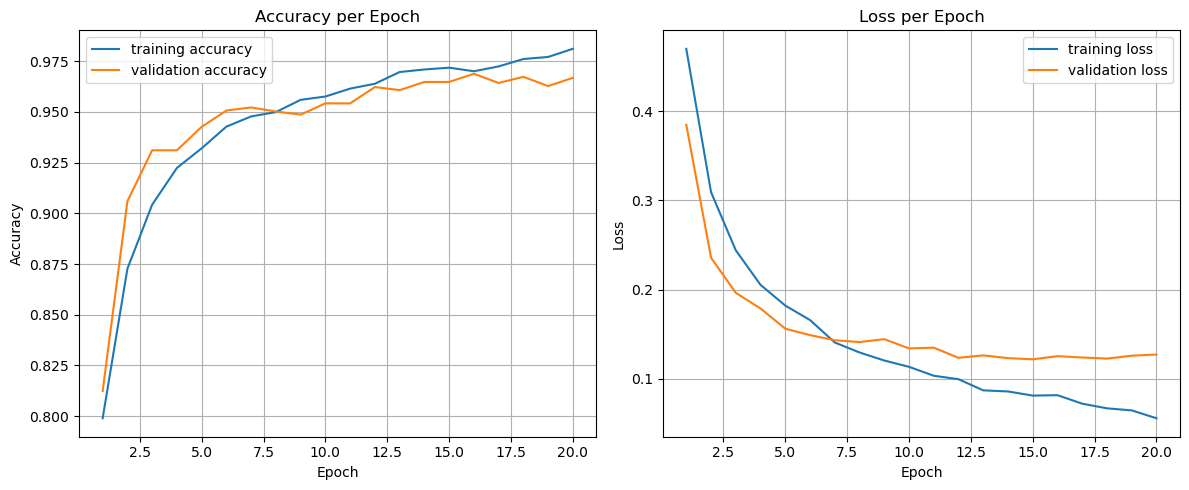

In [177]:
plt.figure(figsize=(12,5))
epochs = range(1, len(history.history['loss']) + 1)

# Accuracy plot per epoch
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['accuracy'], label='training accuracy')
plt.plot(epochs, history.history['val_accuracy'], label='validation accuracy')
plt.title("Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot per epoch
plt.subplot(1, 2, 2)
plt.plot(epochs, history.history['loss'], label='training loss')
plt.plot(epochs, history.history['val_loss'], label='validation loss')
plt.title("Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

63/63 [==============================] - 14s 223ms/step
              precision    recall  f1-score   support

without_mask       0.99      0.95      0.97       994
   with_mask       0.95      0.99      0.97       994

    accuracy                           0.97      1988
   macro avg       0.97      0.97      0.97      1988
weighted avg       0.97      0.97      0.97      1988

Confusion Matrix:
 [[942  52]
 [ 14 980]]


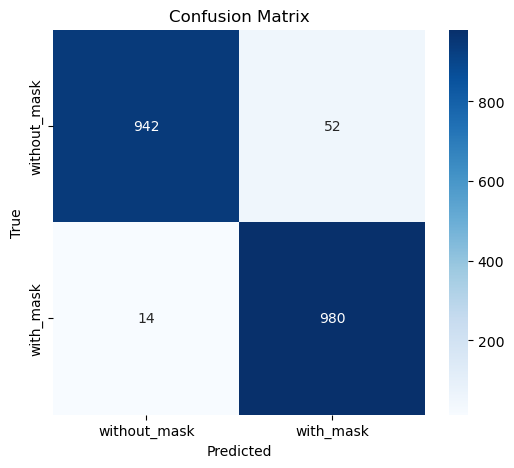

In [178]:
# Confusion matrix
# Create predictions
y_true = np.argmax(y_val, axis=1)
probs = model.predict(X_val)
y_pred = np.argmax(probs, axis=1)

# Print classification report
print(classification_report(y_true, y_pred, target_names=categories))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

# Plot heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=categories,
    yticklabels=categories
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [179]:
# Display images with the model's predictions.
# Shows predicted class, confidence score, and true label.
def show_predictions_numpy(model, X, y, class_names, n_samples=10):
    # y can be one-hot or integer labels
    if y.ndim == 2:
        true_labels = np.argmax(y, axis=1)
    else:
        true_labels = y

    n_samples = min(n_samples, X.shape[0])
    indices = np.random.choice(X.shape[0], n_samples, replace=False)

    images_batch = X[indices]
    labels_batch = true_labels[indices]

    # Run predictions: (n_samples, num_classes)
    probs = model.predict(images_batch)
    pred_classes = np.argmax(probs, axis=1)
    confidences = probs[np.arange(n_samples), pred_classes] * 100.0

    plt.figure(figsize=(14, 8))

    for i in range(n_samples):
        ax = plt.subplot(2, n_samples // 2, i + 1)

        img = images_batch[i]

        # img shape: (100, 100, 1) → squeeze for grayscale
        if img.shape[-1] == 1:
            plt.imshow(img.squeeze(-1), cmap="gray")
        else:
            plt.imshow(img)

        title_text = (
            f"Pred: {class_names[pred_classes[i]]} ({confidences[i]:.1f}%)\n"
            f"True: {class_names[labels_batch[i]]}"
        )

        plt.title(title_text, fontsize=10)
        plt.axis("off")

    plt.tight_layout(pad=3.0)
    plt.show()

1/1 [==============================] - 0s 211ms/step


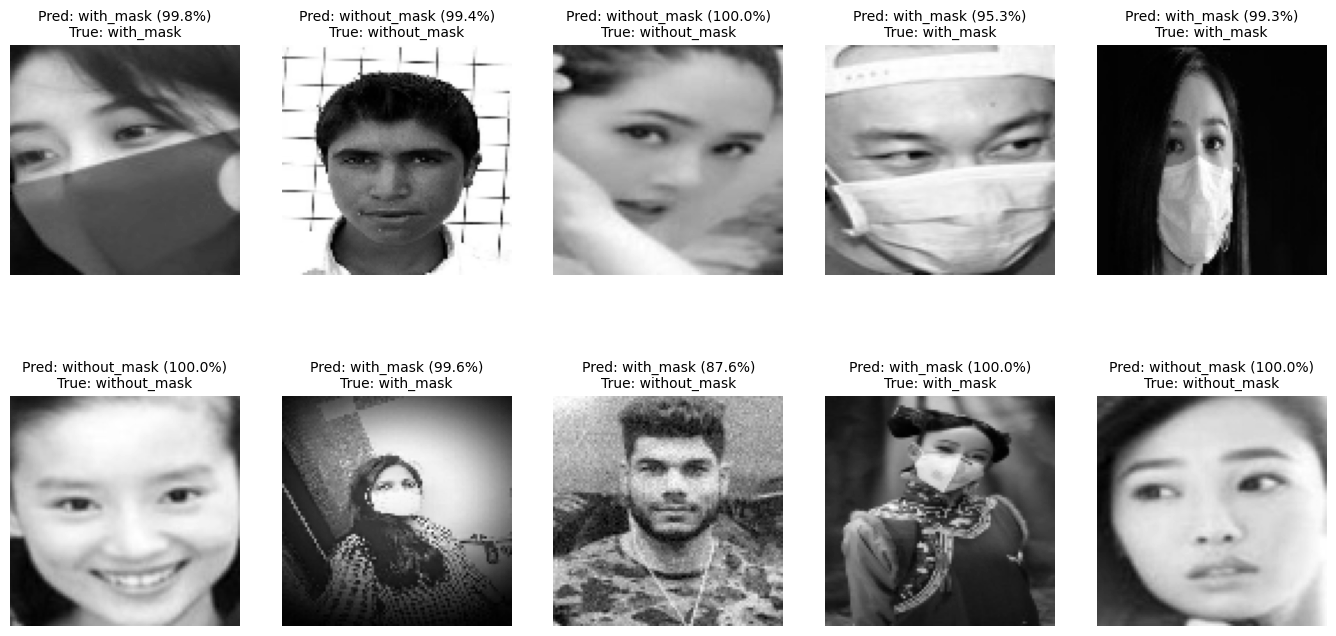

In [180]:
show_predictions_numpy(model, X_val, y_val, categories, n_samples=10)

1/1 [==============================] - 0s 179ms/step


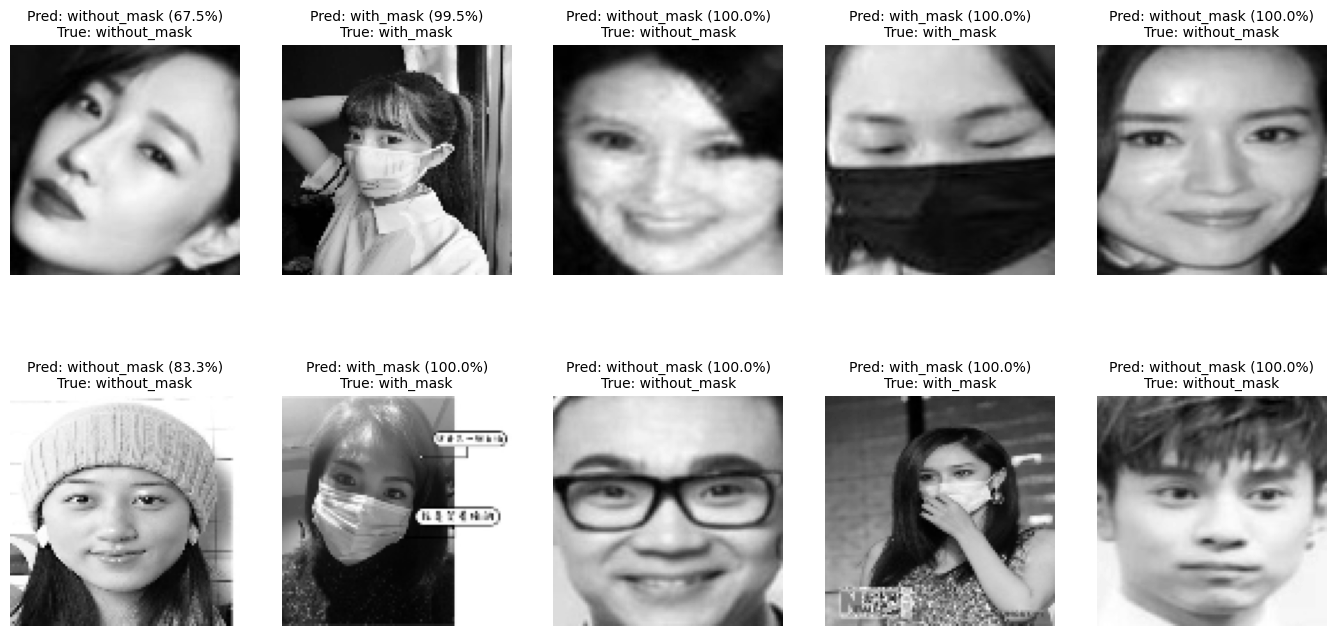

In [181]:
show_predictions_numpy(model, X_test, y_test, categories, n_samples=10)